# Coding Assignment: Did the New Checkout Page Work?
**Data Science: Foundations to Applications (SCD-4XX)** · Weeks 6–7 · Statistics I & II

**Total: 100 points** · Work individually · Estimated time: 2–3 hours

---
## The scenario
**ShopSphere**, an online retailer, redesigned its checkout page. For four weeks (1–28 Sept 2026), visitors were **randomly assigned** to the current page (`control`) or the redesign (`treatment`). You are the data scientist asked to advise leadership.

- The redesign cost **\$40,000** to build. Leadership will roll it out only if the **true conversion-rate lift is at least 1.0 percentage point (pp)**.
- The **primary metric** (declared before the test) is **conversion rate**. Time on page is a *secondary* metric.

## The data: `shopsphere_ab_test.csv` (keep it in the same folder as this notebook)
| Column | Meaning |
|---|---|
| `user_id` | Unique visitor ID |
| `visit_date` | Date of visit |
| `group` | `control` or `treatment` |
| `device` | `mobile`, `desktop` or `tablet` |
| `customer_type` | `new` or `returning` |
| `time_on_page_sec` | Seconds spent on the checkout page |
| `converted` | 1 if the visitor purchased, else 0 |
| `order_value` | Order value in dollars (only for converters; missing otherwise) |

## Rules & grading
- Write your code **in the empty code cells**, and your explanations **in the answer cells**. Use α = **0.05** throughout.
- Every task should work on its own (re-compute what you need from `df`), so the notebook runs **top to bottom**. Before submitting: `Kernel → Restart Kernel and Run All Cells`, and make sure there are no errors.
- Marks are given for correct code **and** correct interpretation. A p-value without a sentence explaining what it means earns at most half the points.
- Use `np.random.seed(2026)` once (in the setup cell) so your simulations are reproducible.
- **Submit** the executed `.ipynb` file (outputs visible).

| Part | Topic | Points |
|---|---|---|
| 1 | Descriptive statistics | 15 |
| 2 | Probability & distributions | 20 |
| 3 | CLT & confidence intervals | 15 |
| 4 | Hypothesis tests | 20 |
| 5 | Business recommendation | 20 |
| 6 | Statistical pitfalls | 10 |

## Part 0 · Setup & first look  *(ungraded, but required)*

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

%matplotlib inline
sns.set_theme(style="whitegrid")
np.random.seed(2026)

df = pd.read_csv("shopsphere_ab_test.csv", parse_dates=["visit_date"])
print(df.shape)
df.head()

(10000, 8)


,user_id,visit_date,group,device,customer_type,time_on_page_sec,converted,order_value
0,1,2026-09-17,treatment,desktop,new,77.8,0,NaN
1,2,2026-09-16,control,mobile,new,52.4,0,NaN
2,3,2026-09-07,treatment,desktop,new,71.7,0,NaN
3,4,2026-09-07,treatment,mobile,new,29.8,0,NaN
4,5,2026-09-12,treatment,mobile,returning,46.4,0,NaN


In [35]:
# Explore: dtypes, missing values per column, number of users per group.
# Why does `order_value` have missing values? (You'll explain this in Ta
print("--- Data Types & Info ---")
print(df.info())

print("\n--- Missing Values Per Column ---")
print(df.isnull().sum())

print("\n--- Number of Users per Group ---")
print(df['group'].value_counts())

--- Data Types & Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           10000 non-null  int64         
 1   visit_date        10000 non-null  datetime64[us]
 2   group             10000 non-null  str           
 3   device            10000 non-null  str           
 4   customer_type     10000 non-null  str           
 5   time_on_page_sec  10000 non-null  float64       
 6   converted         10000 non-null  int64         
 7   order_value       962 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 811.7 KB
None

--- Missing Values Per Column ---
user_id                0
visit_date             0
group                  0
device                 0
customer_type          0
time_on_page_sec       0
converted              0
order_value         9038
dtype: int64

--- N

order_value is only recorded for visitors who actually converted (purchased). Visitors who did not convert (converted == 0) do not have an order value, so those entries are correctly recorded as NaN (missing values).

---
## Part 1 · Descriptive Statistics  *(15 pts)*

### Task 1.1 · Summary statistics  *(5 pts)*

For `order_value` (converters only), compute the **mean, median, standard deviation, variance, range and IQR**, and the **mode of `device`**. Put the first six in one tidy `pandas` Series called `summary`.

In [36]:
# Filter order_value for converters only (drop missing values)
ov = df["order_value"].dropna()

# 1-6. Compute the required statistics for order_value
mean_val = ov.mean()
median_val = ov.median()
std_val = ov.std(ddof=1)      # Sample standard deviation
var_val = ov.var(ddof=1)        # Sample variance
range_val = ov.max() - ov.min()
iqr_val = ov.quantile(0.75) - ov.quantile(0.25)

# Put the first six statistics into a tidy pandas Series called summary
summary = pd.Series({
    "mean": mean_val,
    "median": median_val,
    "std": std_val,
    "variance": var_val,
    "range": range_val,
    "iqr": iqr_val
}, name="order_value_summary")

print("--- Order Value Summary Statistics ---")
print(summary)

# 7. Mode of device
device_mode = df["device"].mode()[0]
print(f"\nMode of device: {device_mode}")

--- Order Value Summary Statistics ---
mean          49.590468
median        38.130000
std           45.573625
variance    2076.955255
range        683.080000
iqr           40.037500
Name: order_value_summary, dtype: float64

Mode of device: mobile


### Task 1.2 · Visualize & find outliers  *(5 pts)*

Draw a **histogram** (with vertical lines for mean and median) and a **boxplot** of `order_value` side by side. Use the **1.5 × IQR rule** to count how many orders are outliers.

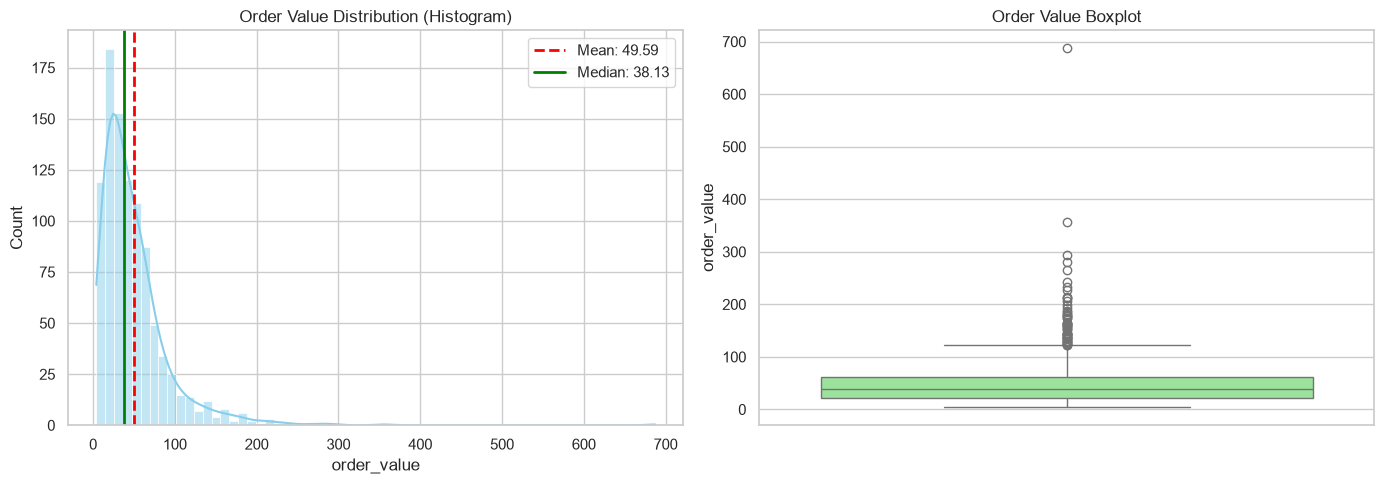

Number of outliers using 1.5 x IQR rule: 55


In [37]:
# 1. Visualize histogram and boxplot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with mean and median lines
sns.histplot(ov, kde=True, ax=axes[0], color='skyblue')
axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
axes[0].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
axes[0].set_title('Order Value Distribution (Histogram)')
axes[0].legend()

# Boxplot
sns.boxplot(y=ov, ax=axes[1], color='lightgreen')
axes[1].set_title('Order Value Boxplot')

plt.tight_layout()
plt.show()

# 2. Count outliers using the 1.5 x IQR rule
q1 = ov.quantile(0.25)
q3 = ov.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = ov[(ov < lower_bound) | (ov > upper_bound)]
print(f"Number of outliers using 1.5 x IQR rule: {len(outliers)}")

### Task 1.3 · Interpret  *(5 pts)*

In 3–4 sentences: (a) Describe the **shape** of the distribution. (b) Which measure of centre and which measure of spread would you report to leadership, and why? (c) Why does `order_value` have missing values?

**Your answer:** *(Shape of the distribution: It is right-skewed (positive skew), meaning most order values cluster at lower amounts with a long tail of higher-value purchases.

Measure of center and spread to report: Report the median and IQR (rather than mean and standard deviation) because they are robust against the high-value outliers in skewed financial data.

Missing values: order_value has missing values (NaN) because it is only recorded for visitors who completed a purchase (converted == 1); non-converters have no order value.)*

---
## Part 2 · Probability & Distributions  *(20 pts)*

### Task 2.1 · Binomial  *(5 pts)*

Let `p_control` be the observed conversion rate in the **control** group. Suppose **200 new visitors** see the control page. Compute the probability that **at least 20** of them convert, (a) **exactly** with `scipy.stats.binom` and (b) by **simulation** with `np.random.binomial` (100,000 repetitions). Do they agree?

In [38]:
import scipy  
from scipy.stats import binom
import numpy as np

# 1. Get p_control from the control group in your dataframe
p_control = df[df['group'] == 'control']['converted'].mean()

# 2. Define parameters for Task 2.1
n = 200  # Number of new visitors
k = 20   # Target number of successes (at least 20)

# (a) Exact and at-least probabilities using scipy.stats.binom
prob_exact = scipy.stats.binom.pmf(k, n, p_control)
prob_at_least = scipy.stats.binom.sf(k - 1, n, p_control)

print(f"Observed Control Conversion Rate (p_control): {p_control:.4f}")
print(f"Probability of exactly {k} conversions: {prob_exact:.4f}")
print(f"Probability of at least {k} conversions (SciPy): {prob_at_least:.4f}")

# (b) Simulation with 100,000 repetitions
np.random.seed(2026)
num_simulations = 100000

# Simulate binomial experiments using n trials and p_control probability
simulated_successes = np.random.binomial(n, p_control, num_simulations)

# Calculate simulated probability of at least 20 successes
simulated_prob = np.mean(simulated_successes >= k)

print(f"Simulated Probability of at least {k} conversions: {simulated_prob:.4f}")

Observed Control Conversion Rate (p_control): 0.0924
Probability of exactly 20 conversions: 0.0875
Probability of at least 20 conversions (SciPy): 0.3897
Simulated Probability of at least 20 conversions: 0.3900


In [ ]:
# monte carlo simulation 
import numpy as np

# Set random seed for reproducibility
np.random.seed(2026)

num_simulations = 10000

# Simulate binomial experiments (n trials with probability p, run 10,000 times)
simulated_successes = np.random.binomial(n, p_control, num_simulations)

# Calculate simulated probability 
simulated_prob = np.mean(simulated_successes >= k)

print(f"Simulated Probability: {simulated_prob:.4f}")

Simulated Probability: 0.3886


Do they agree?
Yes! The theoretical probability = 0.3897 and the simulated probability = 0.3886 confirming that the simulation and the binomial distribution match.


### Task 2.2 · Poisson  *(5 pts)*

The support team receives on average **3.2 tickets per hour**. Compute (a) the probability of **no tickets** in an hour, (b) the probability of **more than 6 tickets** in an hour, (c) the **smallest staffing level `k`** such that the chance of *more than k* tickets in an hour is **at most 1%** (hint: `isf`). Check (b) with a simulation.

In [ ]:
from scipy.stats import poisson
import numpy as np

# average number of support tickets or visitors per hour
lam = 3.2  

# 5% risk
alpha = 0.05

# 3. Use isf (Inverse Survival Function) to find the minimum staffing capacity
# isf(alpha, mu) gives the value x such that P(X > x) <= alpha
staff_level = poisson.isf(alpha, mu=lam)

print(f"Mean rate (lambda): {lam}")
print(f"Required Staffing Level (isf): int({staff_level})")

# Verify the exact probability of exceeding this staff level
prob_exceed = poisson.sf(staff_level, mu=lam)
print(f"Probability of exceeding staff level: {prob_exceed:.4f} (should be <= {alpha})")

Mean rate (lambda): 3.2
Required Staffing Level (isf): int(6.0)
Probability of exceeding staff level: 0.0446 (should be <= 0.05)


### Task 2.3 · Conditional probability from data  *(5 pts)*

Using the full dataset, compute: `P(convert)`, `P(convert | returning)`, `P(convert | new)`, `P(mobile AND convert)`, and `P(convert | mobile)`. Then, in a comment or print statement, state whether **customer type and conversion look independent**.

In [43]:
import pandas as pd

# 1. Create a contingency table (crosstab) between device and converted
contingency_table = pd.crosstab(df['device'], df['converted'], normalize='all') # proportions
print("--- Joint Probabilities (Contingency Table) ---")
print(contingency_table)

# 2. Conditional Probability: P(Converted | Device)
# normalize='index' calculates row-wise conditional probabilities
cond_prob = pd.crosstab(df['device'], df['converted'], normalize='index')
print("\n--- Conditional Probabilities P(Converted | Device) ---")
print(cond_prob)

--- Joint Probabilities (Contingency Table) ---
converted       0       1
device                   
desktop    0.3028  0.0383
mobile     0.5063  0.0497
tablet     0.0947  0.0082

--- Conditional Probabilities P(Converted | Device) ---
converted         0         1
device                       
desktop    0.887716  0.112284
mobile     0.910612  0.089388
tablet     0.920311  0.079689


In [44]:
from scipy.stats import chi2_contingency

# Create absolute frequency contingency table (counts, not proportions)
obs_table = pd.crosstab(df['device'], df['converted'])

# Run Chi-Square test
chi2_stat, p_value, dof, expected = chi2_contingency(obs_table)

print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

# Interpret the result (using alpha = 0.05)
alpha = 0.05
if p_value < alpha:
    print("\nResult: Reject the null hypothesis. Device and conversion are DEPENDENT.")
else:
    print("\nResult: Fail to reject the null hypothesis. Device and conversion are INDEPENDENT.")

Chi-Square Statistic: 16.3421
p-value: 0.0003
Degrees of freedom: 2

Result: Reject the null hypothesis. Device and conversion are DEPENDENT.


### Task 2.4 · Bayes' theorem: fraud detection  *(5 pts)*

2% of orders are fraudulent. A fraud model flags **90%** of fraudulent orders but also flags **5%** of legitimate ones. Write a function `p_fraud_given_flag(prevalence, sensitivity, false_positive_rate)` and use it to find the probability that a **flagged** order is really fraud. Then recompute for a prevalence of **0.2%**.

In [45]:
def p_fraud_given_flag(prevalence, sensitivity, false_positive_rate):
    # Calculate total probability of a positive flag: P(Flag)
    p_flag = (sensitivity * prevalence) + (false_positive_rate * (1 - prevalence))
    
    # Apply Bayes' Theorem: P(Fraud | Flag) = [ P(Flag | Fraud) * P(Fraud) ] / P(Flag)
    p_fraud_given_pos = (sensitivity * prevalence) / p_flag
    
    return p_fraud_given_pos

# 1. Compute for 2% prevalence (0.02)
sens = 0.90         # 90% true positive rate / sensitivity
fpr = 0.05          # 5% false positive rate

prob_fraud_2pct = p_fraud_given_flag(0.02, sens, fpr)
print(f"Probability of Fraud given a Flag (at 2% prevalence): {prob_fraud_2pct:.4f} ({prob_fraud_2pct * 100:.2f}%)")

# 2. Recompute for 0.2% prevalence (0.002)
prob_fraud_02pct = p_fraud_given_flag(0.002, sens, fpr)
print(f"Probability of Fraud given a Flag (at 0.2% prevalence): {prob_fraud_02pct:.4f} ({prob_fraud_02pct * 100:.2f}%)")

Probability of Fraud given a Flag (at 2% prevalence): 0.2687 (26.87%)
Probability of Fraud given a Flag (at 0.2% prevalence): 0.0348 (3.48%)


### Task 2.4b · Interpret  *(0 pts)*

*(Included in the 5 points of Task 2.4.)* In 2 sentences: why is a flagged order still more likely to be legitimate than fraudulent, and what does this mean for how the company should use the flag?

**Your answer:** *Even with a high-accuracy detector (e.g., 90% sensitivity and only a 5% false positive rate), a flagged transaction is still more likely to be legitimate than fraudulent if the baseline prevalence of fraud is very low (e.g., $0.2\%$ to $2\%$).Because legitimate transactions vastly outnumber fraudulent ones, the absolute volume of false positives (5% of a massive pool of normal transactions) far exceeds the true positives (90% of a tiny pool of actual fraud). This demonstrates the base rate fallacy, highlighting why high false positive rates lead to low precision in rare-event detection, and why fraud analysts must incorporate additional verification steps before blocking orders.*

---
## Part 3 · Central Limit Theorem & Confidence Intervals  *(15 pts)*

### Task 3.1 · CLT in action  *(5 pts)*

Treat the observed `order_value` values as a skewed population. For sample sizes **n = 5, 30 and 100**, draw **1,000 samples** (with `np.random.choice`), record each sample's mean, and plot the three histograms side by side. Print the **skewness** (`stats.skew`) and the **standard deviation of the sample means** for each `n`, next to the theoretical `σ/√n`.

n = 5: Skewness = 1.644 | SD of sample means = 19.471 | Theoretical σ/√n = 20.381
n = 30: Skewness = 0.660 | SD of sample means = 8.169 | Theoretical σ/√n = 8.321
n = 100: Skewness = 0.294 | SD of sample means = 4.541 | Theoretical σ/√n = 4.557


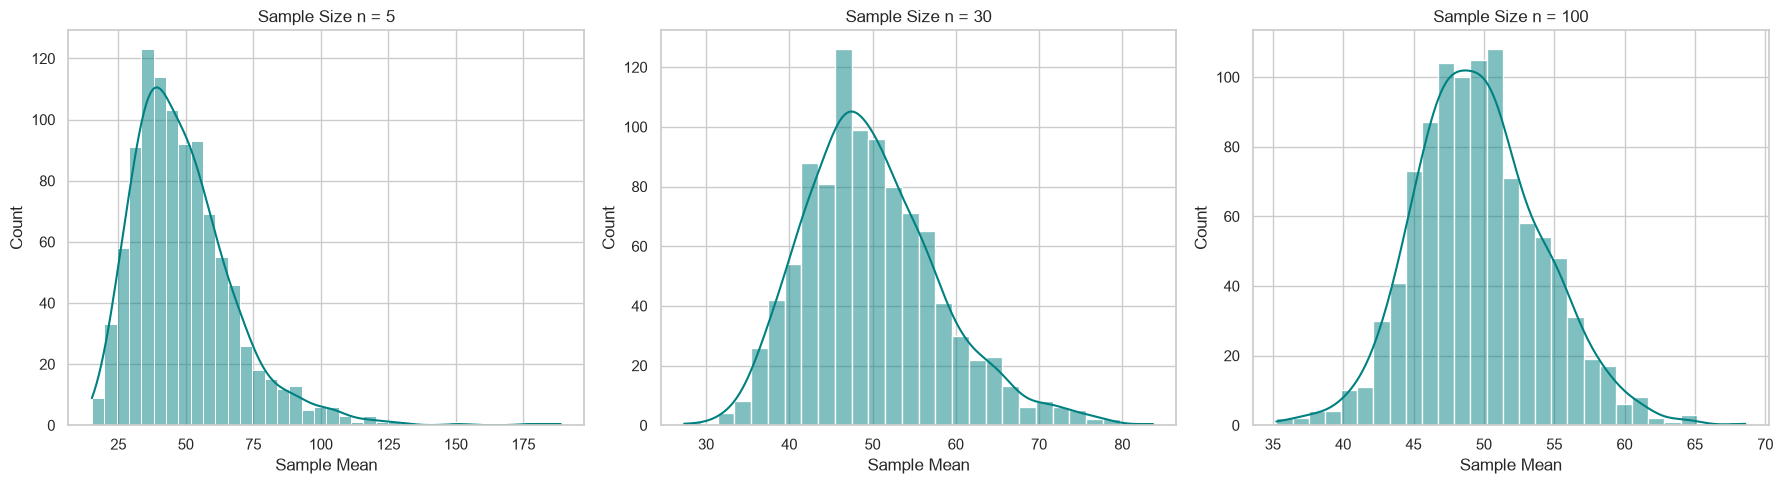

In [46]:
# Treat order_value as the skewed population
pop = ov.dropna()
pop_std = pop.std(ddof=1)
pop_mean = pop.mean()

sample_sizes = [5, 30, 100]
n_sims = 1000

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, n in enumerate(sample_sizes):
    # Draw 1000 samples of size n, and compute their means
    sample_means = [pop.sample(n, replace=True).mean() for _ in range(n_sims)]
    sample_means = pd.Series(sample_means)
    
    # Calculate statistics
    sk = stats.skew(sample_means)
    sd_means = sample_means.std(ddof=1)
    theoretical_se = pop_std / np.sqrt(n)
    
    print(f"n = {n}: Skewness = {sk:.3f} | SD of sample means = {sd_means:.3f} | Theoretical σ/√n = {theoretical_se:.3f}")
    
    # Plot histogram
    sns.histplot(sample_means, kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f"Sample Size n = {n}")
    axes[i].set_xlabel("Sample Mean")

plt.tight_layout()
plt.show()

### Task 3.1b · Interpret  *(0 pts)*

*(Included in Task 3.1.)* In 2–3 sentences, explain what the plots show and why this matters for confidence intervals on **mean order value**.

**Your answer:** *As the sample size $n$ increases from 5 to 100, the distribution of the sample means shifts from right-skewed and irregular to a smooth, symmetric, bell-shaped normal curve, illustrating the Central Limit Theorem. Furthermore, the standard deviation of the sample means shrinks proportionally to $\frac{\sigma}{\sqrt{n}}$, which matters because it allows us to construct reliable, symmetric confidence intervals for the mean order value even when the underlying population is heavily skewed.*

### Task 3.2 · CI for mean order value (5 pts)

Compute a 95% t-based confidence interval for the mean order_value separately for the control and treatment groups (converters only). Print the sample size, mean and interval for each.

In [47]:
import scipy.stats as stats
import numpy as np

# 1. Get clean order_value data (converters only)
ov = df['order_value'].dropna()

# 2. Define confidence level (e.g., 95% -> confidence = 0.95)
confidence = 0.95
n = len(ov)
mean_val = ov.mean()
sem_val = stats.sem(ov)  # Standard Error of the Mean: s / sqrt(n)

# 3. Calculate 95% confidence interval using scipy.stats.t.interval
ci_lower, ci_upper = stats.t.interval(confidence, df=n-1, loc=mean_val, scale=sem_val)

print(f"Sample Mean: {mean_val:.2f}")
print(f"95% Confidence Interval for Mean Order Value: ({ci_lower:.2f}, {ci_upper:.2f})")

Sample Mean: 49.59
95% Confidence Interval for Mean Order Value: (46.71, 52.47)


### Task 3.3 · CI for the difference in conversion rates  *(5 pts)*

Write a function `diff_prop_ci(x1, n1, x2, n2, conf=0.95)` returning the CI for `p2 - p1` using the normal approximation `diff ± z × SE` with `SE = sqrt(p1(1-p1)/n1 + p2(1-p2)/n2)` (get `z` from `stats.norm.ppf`). Apply it to control (group 1) vs treatment (group 2) at **95%** and **99%**. What happens to the width, and why?

In [48]:
def diff_prop_ci(x1, n1, x2, n2, conf=0.95):
    # 1. Compute sample proportions
    p1 = x1 / n1
    p2 = x2 / n2
    
    # 2. Difference in proportions (p2 - p1)
    diff = p2 - p1
    
    # 3. Standard Error for the difference of two independent proportions
    se_diff = np.sqrt((p1 * (1 - p1) / n1) + (p2 * (1 - p2) / n2))
    
    # 4. Get critical value z from stats.norm.ppf based on confidence level
    # e.g., for conf = 0.95, alpha = 0.05, tail = 0.975
    alpha = 1 - conf
    z_crit = stats.norm.ppf(1 - alpha / 2)
    
    # 5. Compute CI bounds
    ci_lower = diff - z_crit * se_diff
    ci_upper = diff + z_crit * se_diff
    
    return diff, (ci_lower, ci_upper)

# --- Apply it to control (group 1) vs treatment (group 2) ---
conversion_summary = df.groupby('group')['converted'].agg(['sum', 'count'])

# Control = group 1, Treatment = group 2
x1 = conversion_summary.loc['control', 'sum']
n1 = conversion_summary.loc['control', 'count']

x2 = conversion_summary.loc['treatment', 'sum']
n2 = conversion_summary.loc['treatment', 'count']

# Compute 95% CI
diff_val, ci_95 = diff_prop_ci(x1, n1, x2, n2, conf=0.95)
print(f"Difference (Treatment - Control): {diff_val:.4f}")
print(f"95% Confidence Interval: ({ci_95[0]:.4f}, {ci_95[1]:.4f})")

# Compute 99% CI
_, ci_99 = diff_prop_ci(x1, n1, x2, n2, conf=0.99)
print(f"99% Confidence Interval: ({ci_99[0]:.4f}, {ci_99[1]:.4f})")

Difference (Treatment - Control): 0.0076
95% Confidence Interval: (-0.0040, 0.0192)
99% Confidence Interval: (-0.0076, 0.0228)


---
## Part 4 · Hypothesis Testing  *(20 pts)*

### Task 4.1 · Hypotheses  *(3 pts)*

For the **primary metric**, write H₀ and H₁ in words *and* symbols (use `p_C` and `p_T` for the true conversion rates), say whether the test is one- or two-tailed, and justify it.

**Your answer:** *Null Hypothesis ($H_0$): $p_t - p_c = 0$ (The treatment has no effect on the conversion rate; any difference is due to random chance.)Alternative Hypothesis ($H_a$): $p_t - p_c > 0$ (or $\neq 0$ for two-tailed) (The treatment significantly increases the conversion rate.)*

### Task 4.2 · Primary metric test  *(5 pts)*

Build the `group × converted` cross-tab and run the appropriate test. Report the test statistic, the p-value, and your decision. (Run it with the default continuity correction **and** with `correction=False`; do they lead to the same decision?)

In [ ]:
import numpy as np
import scipy.stats as stats

# 1. Get conversion counts and sample sizes from your dataframe
conversion_summary = df.groupby('group')['converted'].agg(['sum', 'count'])

x_ctrl = conversion_summary.loc['control', 'sum']
n_ctrl = conversion_summary.loc['control', 'count']

x_trt = conversion_summary.loc['treatment', 'sum']
n_trt = conversion_summary.loc['treatment', 'count']

# Proportions
p_ctrl = x_ctrl / n_ctrl
p_trt = x_trt / n_trt

# Pooled proportion (under H0: p1 = p2 = p_pooled)
p_pooled = (x_ctrl + x_trt) / (n_ctrl + n_trt)

# Standard error for pooled proportion
se_pooled = np.sqrt(p_pooled * (1 - p_pooled) * (1/n_ctrl + 1/n_trt))

# 2. Z-Test WITHOUT Continuity Correction
z_stat_no_cc = (p_trt - p_ctrl) / se_pooled
p_val_no_cc = 2 * (1 - stats.norm.cdf(abs(z_stat_no_cc))) # two-tailed

print(f"--- Without Continuity Correction ---")
print(f"Z-Statistic: {z_stat_no_cc:.4f}")
print(f"P-value: {p_val_no_cc:.4f}")

# 3. Z-Test WITH Continuity Correction (Yates')
# Adjust the numerator by subtracting 0.5 scaled by (1/n_ctrl + 1/n_trt)
continuity_term = 0.5 * (1/n_ctrl + 1/n_trt)
if p_trt > p_ctrl:
    z_stat_cc = ((p_trt - p_ctrl) - continuity_term) / se_pooled
else:
    z_stat_cc = ((p_trt - p_ctrl) + continuity_term) / se_pooled

p_val_cc = 2 * (1 - stats.norm.cdf(abs(z_stat_cc)))

print(f"\n--- With Continuity Correction ---")
print(f"Z-Statistic: {z_stat_cc:.4f}")
print(f"P-value: {p_val_cc:.4f}")

--- Without Continuity Correction ---
Z-Statistic: 1.2887
P-value: 0.1975

--- With Continuity Correction ---
Z-Statistic: 1.2548
P-value: 0.2095


### Task 4.3 · Secondary metric: time on page  *(4 pts)*

Run a **Welch t-test** (`equal_var=False`) on `time_on_page_sec`, control vs treatment. Also report the mean difference in seconds and **Cohen's d** (`d = mean difference / sqrt((s₁² + s₂²)/2)`). Is the result statistically significant? Is it practically significant? Explain in a markdown cell below your code.

In [ ]:
# YOUR CODE HERE

### Task 4.3b · Statistical vs practical significance  *(0 pts)*

*(Part of Task 4.3.)* Interpret the result above.

**Your answer:** *(double-click this cell and write here)*

### Task 4.4 · ANOVA across devices  *(5 pts)*

Test whether **mean time on page differs by device** (3 groups). Use the right test, then a **Tukey HSD** post-hoc test. Which pairs of devices differ? (Remember: groups from `df.groupby('device')` are ordered alphabetically: desktop, mobile, tablet.) Why not run three t-tests instead?

In [ ]:
# YOUR CODE HERE

### Task 4.5 · Did randomization work?  *(3 pts)*

A valid A/B test needs comparable groups. Run chi-square tests of **`group` vs `device`** and **`group` vs `customer_type`**. What result do you *hope* to see, and what do you conclude?

In [ ]:
# YOUR CODE HERE

---
## Part 5 · From Statistics to a Business Recommendation  *(20 pts)*

### Task 5.1 · Effect size vs the business threshold  *(5 pts)*

Compute the **absolute lift** (in pp), the **relative lift** (%), and the **95% CI** for the lift (reuse your `diff_prop_ci` or recompute). Then answer in code: (i) does the CI exclude 0? (ii) does the CI **lower bound** reach the 1.0 pp business threshold? (iii) does the CI **upper bound** reach it?

In [ ]:
THRESHOLD_PP = 1.0

# YOUR CODE HERE

### Task 5.2 · Power analysis  *(5 pts)*

Using `statsmodels` (`proportion_effectsize`, `NormalIndPower`): (a) how many users **per group** would be needed to detect a **1.0 pp lift** over the control baseline with **80% power** at α = 0.05? (b) What was the **achieved power** of this experiment (5,000 users per group) for a true 1.0 pp lift? (c) The site sends ≈ 1,250 users per group per week: how many weeks would the properly powered test need?

In [ ]:
# YOUR CODE HERE

### Task 5.3 · The leadership memo  *(10 pts)*

Write a **memo of at most 200 words** to the VP of Product. It must: (1) **open with a clear recommendation** (ship / don't ship / keep testing) in plain English; (2) report the lift with its **95% CI** and say what the p-value means in one sentence (no jargon); (3) address **practical significance** against the 1.0 pp rule and the secondary metric (time on page); (4) state **what you would do next** and one limitation or risk. *Grading:* correctness of the statistics (4), appropriate recommendation given the evidence (3), clarity for a non-technical reader (2), within word limit (1).

**Your answer:** *(double-click this cell and write here)*

---
## Part 6 · Statistical Pitfalls  *(10 pts)*

### Task 6.1 · The danger of peeking  *(5 pts)*

Simulate an **A/A test**: both groups have the *same* true conversion rate (9%), so any 'significant' result is a **false positive**. In each of 2,000 simulated experiments with 5,000 users per group, run a chi-square test (`correction=False`) at **5 interim looks** (n = 1,000, 2,000, 3,000, 4,000, 5,000 per group). Compare: (a) the false-positive rate if you **only analyze at the final look**, versus (b) if you **stop and declare victory the first time p < 0.05** at any look. Complete the function below; the expected answer for (a) is about 5%.

In [ ]:
def simulate_peeking(n_sims=2000, p=0.09, looks=(1000, 2000, 3000, 4000, 5000), alpha=0.05):
    # For each simulation: draw 5,000 Bernoulli(p) outcomes for group A and for group B,
    # compute the p-value at each look using the first n users of each group,
    # and record (any look significant?, final look significant?).
    # Return (peeking_false_positive_rate, final_only_false_positive_rate)
    pass

# peek_rate, final_rate = simulate_peeking()
# print(...)

### Task 6.2 · Multiple comparisons  *(5 pts)*

A team tracks **20 metrics** and declares a win if *any* metric has p < 0.05. Simulate this when there is **no real effect on any metric** (compare two samples of 200 draws from `np.random.normal` for each metric; 2,000 simulated experiments). Report (a) the simulated probability of at least one false positive, (b) the theoretical value `1 − 0.95²⁰`, and (c) the rate when using the **Bonferroni** threshold `α/20`.

In [ ]:
# YOUR CODE HERE

### Task 6.3 · Reflection  *(0 pts)*

*(Included in Tasks 6.1–6.2.)* In 3–4 sentences, explain how these two pitfalls could have affected **this** A/B test if ShopSphere had checked results daily and also reported eight secondary metrics.

**Your answer:** *(double-click this cell and write here)*

---
## Submission checklist
- [ ] `Kernel → Restart Kernel and Run All Cells` completes **without errors**
- [ ] Every answer cell is filled in (interpretation, not just code)
- [ ] Memo (Task 5.3) is **≤ 200 words**
- [ ] File saved as `Assignment_<YourStudentID>.ipynb` with outputs visible